# Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)

### 1. Aim
To sort three distinct random integer arrays using manual Bubble Sort algorithm, benchmarking Sequential execution, multiprocessing.Pool (3 workers), and multiprocessing.Process (3 processes).

### 2. Algorithm / Explanation
1. Generate three independent arrays of 3,200 random integers.<br>2. Implement manual `bubble_sort(arr)` with early-termination optimization.<br>3. **Pattern 2**: Each array is sorted once.<br>4. Sequential: Sort Array 1 -> Array 2 -> Array 3.<br>5. Pool: Sort each array concurrently using 3 workers in `mp.Pool(3)`.<br>6. Process: Sort each array concurrently in 3 independent processes.<br>7. Verify sorting correctness and compare performance.

### 3. Python Implementation


In [1]:
"""
Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)
"""
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def bubble_sort_task(task):
    size, seed = task
    random.seed(seed)
    a = [random.randint(1, 100000) for _ in range(size)]
    n = len(a)
    for i in range(n):
        swapped = False
        for j in range(0, n - i - 1):
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swapped = True
        if not swapped:
            break
    is_sorted = all(a[k] <= a[k + 1] for k in range(n - 1))
    return is_sorted, a[:5]

def proc_worker(task, q):
    q.put(bubble_sort_task(task))

def main():
    print("=" * 60)
    print("Practical 8: Bubble Sort (Pattern 2)")
    print("=" * 60)
    SIZE = 3200
    tasks = [(SIZE, 10), (SIZE, 20), (SIZE, 30)]
    
    # Sequential
    t0 = time.perf_counter()
    r1 = bubble_sort_task(tasks[0])
    r2 = bubble_sort_task(tasks[1])
    r3 = bubble_sort_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # Pool
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(bubble_sort_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # Process
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    print(f"Sorted 3 arrays of {SIZE} random elements each.")
    print(f"Sample sorted first 5: {seq_res[0][1]}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Three Independent Random Arrays: 3,200 integers each
Verification:
  Array 1 Sorted: True | First 5: [60, 73, 74, 75, 103]
  Array 2 Sorted: True | First 5: [11, 32, 50, 60, 116]
  Array 3 Sorted: True | First 5: [1, 16, 103, 107, 193]

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.0395 seconds      1.00x
Pool         1.3917 seconds      1.47x
Process      1.4354 seconds      1.42x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


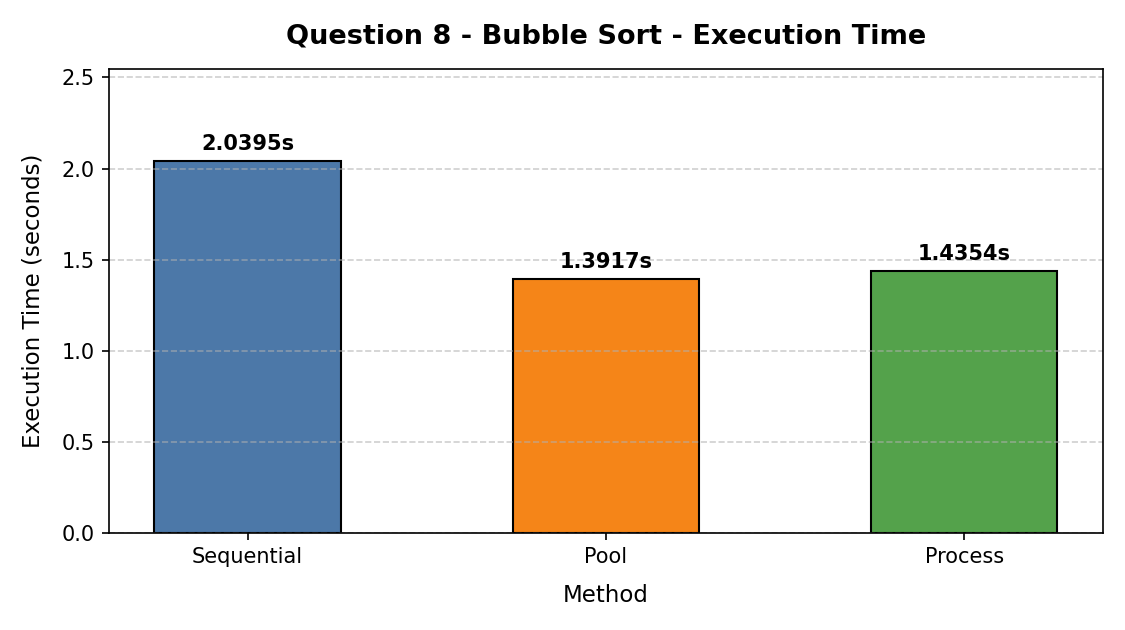

In [2]:
from IPython.display import Image, display
display(Image(filename='08_bubble_sort_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


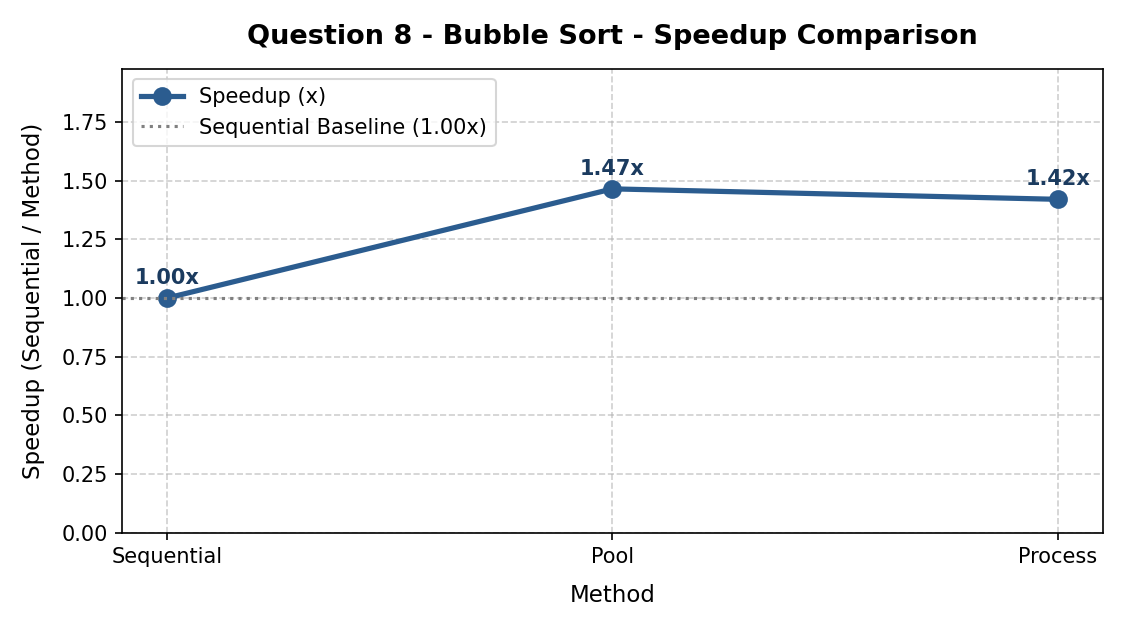

In [3]:
from IPython.display import Image, display
display(Image(filename='08_bubble_sort_speedup.png'))
